# Analysis to find out if our df is clusterable

In [14]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import plotly.express as px

- To analyze whether our dataset (DataFrame) is suitable for clustering, we will use the Hopkins statistic. This statistic is a measure that allows us to evaluate whether the data has a clustering structure (clustering) or if it is randomly distributed in space. A value close to 1 indicates that the data has a well-defined clustering structure, while a value close to 0 suggests that the data is randomly distributed, which would imply that it is not suitable to apply clustering techniques. Therefore, by calculating the Hopkins statistic, we will be able to determine the suitability of our data for the application of clustering methods.

In [15]:
# Función para calcular Hopkins Statistic
def hopkins(X, portion=0.1, seed=247):

    n = X.shape[0]
    d = X.shape[1]
    m = int(portion * n)

    np.random.seed(seed)
    nbrs = NearestNeighbors(n_neighbors=1).fit(X)
    
    # Distancias desde puntos aleatorios generados dentro del rango de los datos
    rand_X = np.random.uniform(X.min(axis=0), X.max(axis=0), size=(m, d))
    u_dist = nbrs.kneighbors(rand_X, return_distance=True)[0]
    
    # Distancias entre puntos reales seleccionados aleatoriamente
    idx = np.random.choice(n, size=m, replace=False)
    w_dist = nbrs.kneighbors(X[idx, :], 2, return_distance=True)[0][:, 1]

    # Cálculo del Hopkins Statistic
    U = (u_dist**d).sum()
    W = (w_dist**d).sum()
    H = U / (U + W)
    return H


# Analysis for Numerical Data

In [16]:
df_numeric=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv',index_col=0)
df_numeric.head()

,age,num.co,edu,charges,totcst,avtisst,hday,meanbp,wblc,hrt,...,pafi,alb,bili,crea,sod,ph,bun,urine,adlsc,Adls_Adlp_merge
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,0,11.000000,9715.0,31100.865401,7.000000,1,97.0,6.000000,69.0,...,388.00000,1.799805,0.199982,1.199951,141.0,7.459961,6.51,2502.0,7.0,7.0
1,60.33899,2,12.000000,34496.0,31100.865401,29.000000,3,43.0,17.097656,112.0,...,98.00000,3.500000,1.010000,5.500000,132.0,7.250000,6.51,2502.0,1.0,1.0
2,52.74698,2,12.000000,41094.0,31100.865401,13.000000,4,70.0,8.500000,88.0,...,231.65625,3.500000,2.199707,2.000000,134.0,7.459961,6.51,2502.0,0.0,0.5
3,42.38498,2,11.000000,3075.0,31100.865401,7.000000,1,75.0,9.099609,88.0,...,333.30000,3.500000,1.010000,0.799927,139.0,7.415340,6.51,2502.0,0.0,0.0
4,79.88495,1,11.749662,50127.0,31100.865401,18.666656,3,59.0,13.500000,112.0,...,173.31250,3.500000,1.010000,0.799927,143.0,7.509766,6.51,2502.0,2.0,2.0


In [17]:
hopkins_score = hopkins(df_numeric.values)
print(f"Hopkins Statistic: {hopkins_score}")

Hopkins Statistic: 0.9999999971564791


### High dimensionality
- In high dimensional datasets, distances between points tend to homogenize due to the curse of dimensionality, making it difficult to detect meaningful patterns or structures, such as clusters. Principal Component Analysis (PCA) is recommended because it reduces dimensionality by projecting the data into a lower dimensional space, preserving as much variability as possible. This eliminates noise and redundant dimensions, improving data separability. In addition, PCA helps to visualize complex datasets and avoid overfitting problems in models.

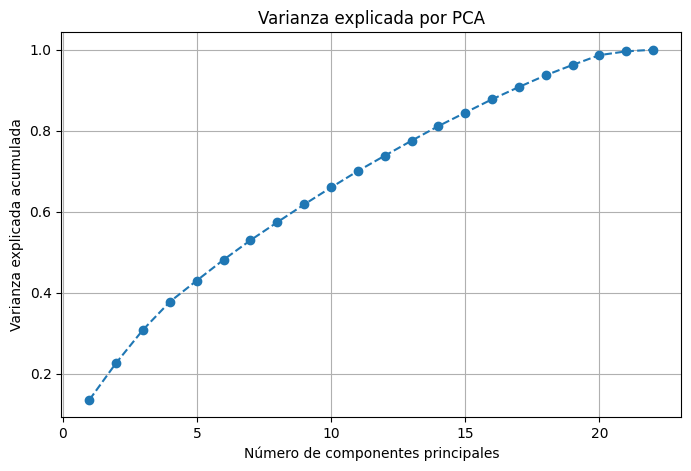

Número óptimo de componentes para explicar el 80% de la varianza: 14


In [18]:
# Estandarización de los datos
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df_numeric)

# Aplicar PCA
pca = PCA()
pca_result = pca.fit_transform(data_scaled)

# Varianza explicada acumulada
explained_variance = pca.explained_variance_ratio_.cumsum()

# Graficar la varianza explicada
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada por PCA')
plt.grid()
plt.show()

# Elegir un número de componentes (ejemplo: 95% de varianza explicada)
num_components = next(i for i, v in enumerate(explained_variance) if v >= 0.80) + 1
print(f'Número óptimo de componentes para explicar el 80% de la varianza: {num_components}')

# Reducir la dimensionalidad
pca_optimal = PCA(n_components=num_components)
data_reduced = pca_optimal.fit_transform(data_scaled)
data_reduced = pd.DataFrame(data_reduced, columns=[f'PC{i}' for i in range(1, num_components + 1)])


In [19]:
data_reduced.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14
0,-1.303120,3.100051,-1.905432,-0.588453,-0.477634,-1.263601,1.208135,0.608772,0.177600,-1.247742,-0.895663,-1.282668,-1.243707,0.137281
1,0.430366,0.129396,2.153589,0.321545,-1.345813,0.985954,-1.061845,-2.870387,0.236929,-0.274228,0.920323,-0.307266,0.367306,0.727948
2,-0.382219,-1.253837,-0.123221,-0.034480,-0.221534,-0.329441,-0.529640,-0.281744,-0.061857,0.658373,-0.291355,0.360485,0.627505,-0.062289
3,-1.401687,-1.516231,-0.167051,-0.540551,0.231418,-0.523062,-0.597440,-1.043009,0.635981,-0.017339,0.158093,-0.888342,0.289797,-1.052352
4,-0.057874,0.022766,-0.812666,0.761205,-0.307166,0.940843,0.604887,1.212452,-0.436952,1.223270,-0.732690,-0.413510,0.487172,0.230605


In [20]:
hopkins_score = hopkins(data_reduced.values)
print(f"Hopkins Statistic: {hopkins_score}")

Hopkins Statistic: 0.9999999997785323


The Hopkins Statistic analysis yields a value of 0.99997, indicating that the dataset has a highly clusterable structure. This indicator evaluates the tendency of the data to group together, with values ​​close to 1 being a strong indicator of clustering patterns. In this case, the result suggests that the data is far from a uniform or random distribution, and presents clear characteristics of cluster formation.

## Visualization of Reduced Dimensionality

At the end of the day, this representation doesn't provide us with much detailed information since we are only visualizing about 30% of the variance. However, despite this limitation, we can still observe the presence of a large cluster. While the reduction in dimensions limits our ability to capture the full complexity of the data, the clustering pattern becomes somewhat apparent in this lower-dimensional space. This suggests that there may be distinct groups or patterns within the data that could be further explored using clustering techniques.

In [21]:
scaler = StandardScaler()
data_scaled = scaler.fit_transform(df_numeric)

# Aplicar PCA para reducir a 3 componentes
pca = PCA(n_components=3)
data_reduced_3 = pca.fit_transform(data_scaled)

# Convertir los resultados a un DataFrame para una mejor visualización
data_reduced_df_3 = pd.DataFrame(data_reduced_3, columns=['PC1', 'PC2', 'PC3'])

# Graficar las 3 primeras componentes de manera interactiva con Plotly
fig = px.scatter_3d(data_reduced_df_3, x='PC1', y='PC2', z='PC3', 
                    title='Proyection of the data in the first 3 principal components',
                    labels={'PC1': 'PC1', 'PC2': 'PC2', 'PC3': 'PC3'})

# Mostrar el gráfico
fig.show()

# Mostrar la varianza explicada por cada componente
print("Variability explained for each component", sum(pca.explained_variance_ratio_)*100)


Variability explained for each component 30.916713338002737


# Analysis for Categorical Data

## Transforming Categorical Variables into Numerical Representations

When working with categorical variables, we need to convert them into numerical formats to make them suitable for analysis. Here are two commonly used techniques:

### 1. **One-Hot Encoding**
   - In this method, each category is transformed into a binary column. 
   - **Advantages**: 
     - Retains all the information about the categories without assuming any relationships between them.
   - **Disadvantages**:
     - If there are many categories or variables, the number of columns can grow significantly, leading to high dimensionality.

### 2. **Ordinal Encoding**
   - This method assigns an integer to each category. For example, `Red` could be represented as `1`, `Blue` as `2`, and `Green` as `3`.
   - **Advantages**:
     - Works well if there is a natural order among the categories (e.g., `Low`, `Medium`, `High`).
   - **Disadvantages**:
     - If there is no inherent order, this approach might introduce unintended biases by implying a hierarchy between categories.

Both techniques have their strengths and weaknesses. The choice between them depends on the context and the type of analysis. If high dimensionality becomes a problem with one-hot encoding, alternative methods like embeddings or distance-based approaches for categorical data might be considered.


In [22]:
df_categorical=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv',index_col=0)
df_categorical.head()

,sex,dzgroup,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,,
0,0,4,1,2,0,2,0,0,0,0,0
1,1,7,3,2,1,0,5,1,1,0,0
2,1,7,3,1,1,0,5,1,0,0,0
3,1,4,1,1,1,2,1,1,0,0,0
4,1,1,4,0,1,0,1,0,0,0,0


- We know that *dzclass* and *dzgroup* are closely related, as *dzgroup* is derived from the aggregation of *dzclass*. Therefore, we have decided to remove the *dzgroup* column to avoid redundancy.

In [23]:
df_categorical=df_categorical.drop(['dzgroup'],axis=1)
df_categorical.head()

,sex,dzclass,income,race,ca,sfdm2,death,hospdead,diabetes,dementia
ID,,,,,,,,,,
0,0,1,2,0,2,0,0,0,0,0
1,1,3,2,1,0,5,1,1,0,0
2,1,3,1,1,0,5,1,0,0,0
3,1,1,1,1,2,1,1,0,0,0
4,1,4,0,1,0,1,0,0,0,0


In [24]:
for col in df_categorical.columns:
    print(f"Column: {col}, unique values: {df_categorical[col].unique()}")

Column: sex, unique values: [0 1]
Column: dzclass, unique values: [1 3 4 2]
Column: income, unique values: [2 1 0 3 4]
Column: race, unique values: [0 1 2 3 4]
Column: ca, unique values: [2 0 1]
Column: sfdm2, unique values: [0 5 1 3 2 4]
Column: death, unique values: [0 1]
Column: hospdead, unique values: [0 1]
Column: diabetes, unique values: [0 1]
Column: dementia, unique values: [0 1]


# Data Preprocessing Plan

## Dummy Columns
The following columns are already represented as dummy variables in the dataset:
- `sex`
- `death`
- `hospdead`
- `diabetes`
- `dementia`
- `ca`
- `dzclass`
- `sfdm2`
- `race`

## Columns to be Ordinally Encoded
The following columns will be transformed using ordinal encoding due to their inherent order:
- `income`

## Additional Transformation
To facilitate further analysis, the `age` column will be transformed into bins representing different age ranges.


In [25]:
df_categorical['age_category'] = pd.cut(df_numeric['age'], bins=10, labels=False)
df_categorical = pd.get_dummies(df_categorical, columns=['ca', 'sfdm2', 'race', 'dzclass'], drop_first=True)

for col in df_categorical.columns:
    if df_categorical[col].dtype == bool:
        # Convertir los valores True/False a 1/0
        df_categorical[col] = df_categorical[col].astype(int)
df_categorical.head()




,sex,income,death,hospdead,diabetes,dementia,age_category,ca_1,ca_2,sfdm2_1,...,sfdm2_3,sfdm2_4,sfdm2_5,race_1,race_2,race_3,race_4,dzclass_2,dzclass_3,dzclass_4
ID,,,,,,,,,,,,,,,,,,,,,
0,0,2,0,0,0,0,5,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,1,2,1,1,0,0,5,0,0,0,...,0,0,1,1,0,0,0,0,1,0
2,1,1,1,0,0,0,4,0,0,0,...,0,0,1,1,0,0,0,0,1,0
3,1,1,1,0,0,0,2,0,1,1,...,0,0,0,1,0,0,0,0,0,0
4,1,0,0,0,0,0,7,0,0,1,...,0,0,0,1,0,0,0,0,0,1


In [26]:
hopkins_score = hopkins(df_categorical.values)
print(f"Hopkins Statistic: {hopkins_score}")

Hopkins Statistic: 0.9999723714924077


The Hopkins Statistic analysis yields a value of 0.99997, indicating that the dataset has a highly clusterable structure. This indicator evaluates the tendency of the data to group together, with values ​​close to 1 being a strong indicator of clustering patterns. In this case, the result suggests that the data is far from a uniform or random distribution, and presents clear characteristics of cluster formation.